# Neural Networks From First Principles

| Key              | Value |
|:-----------------|:------|
| **Course Codes** | BBT 4206 and BFS 4102 |
| **Course Names** | BBT 4206: Business Intelligence II (Week 7-9 of 13)<br>BFS 4102: Advanced Business Data Analytics (Week 1-3 of 13) |
| **Semester**     | September to December 2026 |
| **Lecturer**     | Allan Omondi |
| **Contact**      | aomondi@strathmore.edu |
| **Note**         | The lecture contains both theory and practice.<br/>This notebook forms part of the practice.<br/>It is intended for educational purposes only, and nothing in it is investment advice.<br/>Recommended citation: [BibTex](https://raw.githubusercontent.com/course-files/TimeSeriesForecastingandNeuralNetworks/refs/heads/main/RecommendedCitation.bib) |

## What you will learn in this notebook

This notebook is the foundation for the neural networks in Notebook 6. It uses small artificial datasets on purpose, so that you can see every number and every step. By the end you should be able to:

1. Describe what a **neuron** computes, and compute one by hand.
2. Explain a **loss function**, **gradient descent**, the **learning rate**, and **backpropagation** in plain language, and write them in a few lines of NumPy.
3. Explain why a network needs **hidden layers** and **non-linear activation functions**.
4. Explain **epochs**, **batches**, **validation loss**, **overfitting**, **early stopping**, **L2 regularisation** and **dropout**.
5. Explain how an **RNN**, **LSTM**, **GRU**, **1D CNN** and **attention** read a sequence, and which one to consider for a given problem.
6. Explain why a neural network can reach a low training error even on data that is **pure noise**, and why that matters in finance.

**Prerequisites:** Notebooks 1 to 4 (especially the walk-forward validation and the leakage warnings), and the lecture slides on neural networks, RNNs and LSTMs. Only basic algebra is needed. No calculus is required to follow along, but we do show where it is used.

**Run time:** about 3 to 8 minutes, most of it in Step 10.

## The Big Picture in Four Sentences

1. A neural network is a **function with adjustable numbers** (the **weights**) that turns inputs into a prediction.
2. We measure how wrong the predictions are with a **loss**.
3. We adjust the weights, a little at a time, in the direction that reduces the loss. This is **gradient descent**.
4. We repeat this many times, and we stop when the model stops improving on data it has **not** been trained on.

Everything else in this notebook (layers, activations, LSTMs, attention) is a refinement of those four sentences.

## Step 1: Set Up the Notebook

In [1]:
import os
import sys
import subprocess

print("Python interpreter:", sys.executable)
print("Python version    :", sys.version.split()[0])

# Google Colab starts with an empty workspace, so we fetch the lab files first.
# On your own computer this block does nothing.
if "google.colab" in sys.modules and not os.path.exists("tslab"):
    subprocess.run(["git", "clone", "https://github.com/course-files/TimeSeriesForecastingandNeuralNetworks.git"], check=True)
    os.chdir("TimeSeriesForecastingandNeuralNetworks")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements/colab.txt"], check=True)
    print("Colab workspace prepared.")

Python interpreter: C:\Users\aomondi\Documents\GitHub\Teaching\TimeSeriesForecastingandNeuralNetworks\.venv\Scripts\python.exe
Python version    : 3.12.10


In [2]:
import os
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from tslab import config

import warnings
warnings.filterwarnings("ignore")

%matplotlib inline
plt.rcParams["figure.figsize"] = (11, 4.5)
rng = np.random.default_rng(config.SEED)

## Step 2: A Single Neuron

A neuron does three things.

1. It takes some **inputs** `x1, x2, x3`.
2. It multiplies each input by a **weight** and adds a **bias**: `z = w1*x1 + w2*x2 + w3*x3 + b`. This is just a linear regression equation.
3. It passes `z` through an **activation function** to produce its output `a = f(z)`.

Suppose the inputs are three facts known at the close of today:

- `x1`: today's return of the stock (as a percentage): +1.5
- `x2`: today's change in the VIX (the fear index), in percent: -4.0
- `x3`: today's volume relative to normal: +0.8

and the neuron has the weights `w = [0.4, -0.1, 0.2]` and the bias `b = 0.05`. We compute its output step by step.

In [3]:
x = np.array([1.5, -4.0, 0.8])        # inputs
w = np.array([0.4, -0.1, 0.2])        # weights (these are what the network learns)
b = 0.05                              # bias

z = np.dot(w, x) + b
print("Step 1, multiply each input by its weight:", w * x)
print("Step 2, add them and add the bias        :", round(z, 4))

relu = lambda v: np.maximum(0, v)
print("Step 3, pass through ReLU                :", round(float(relu(z)), 4))

Step 1, multiply each input by its weight: [0.6  0.4  0.16]
Step 2, add them and add the bias        : 1.21
Step 3, pass through ReLU                : 1.21


A single neuron is a weighted vote. Positive weights say "when this input rises, push the output up". Negative weights say the opposite. The **bias** shifts the whole thing up or down. Learning means finding good values for `w` and `b`.

### Activation functions

Without the activation function, a stack of neurons collapses into one big linear equation, however many layers it has (multiplying and adding linear things gives a linear thing). The activation adds a **bend**, and the bends are what let a network represent curves and interactions.

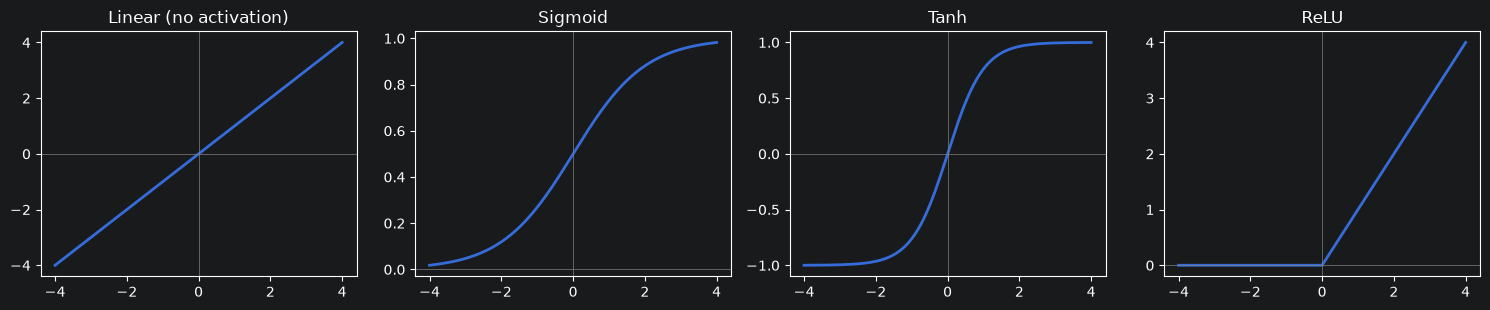

In [4]:
grid = np.linspace(-4, 4, 400)
activations = {
    "Linear (no activation)": grid,
    "Sigmoid": 1 / (1 + np.exp(-grid)),
    "Tanh": np.tanh(grid),
    "ReLU": np.maximum(0, grid),
}
fig, axes = plt.subplots(1, 4, figsize=(15, 3.2), sharex=True)
for ax, (name, values) in zip(axes, activations.items()):
    ax.plot(grid, values, linewidth=2)
    ax.axhline(0, color="grey", linewidth=0.5); ax.axvline(0, color="grey", linewidth=0.5)
    ax.set_title(name)
plt.tight_layout(); plt.show()

| Activation | Output range | Where it is used |
|:-----------|:-------------|:-----------------|
| **Linear** | any number | The output layer of a network that predicts a number, such as a return. |
| **Sigmoid** | 0 to 1 | Gates inside an LSTM (a dial between "closed" and "open"); the output layer for a yes/no probability. |
| **Tanh** | -1 to 1 | The memory content inside an LSTM; older networks. |
| **ReLU** | 0 and up | The default for hidden layers of feed-forward and convolutional networks. It is cheap and does not saturate for positive inputs. |

## Step 3: The Loss, a Single Number That Says How Wrong We Are

For a prediction problem we compare predictions with the true values. The usual loss for a number is the **mean squared error (MSE)**: the average of the squared differences.

`loss = mean( (prediction - truth)^2 )`

We square the errors so that positive and negative errors do not cancel, and so that big mistakes count much more than small ones.

In [5]:
truth      = np.array([0.010, -0.020, 0.005, 0.015])
prediction = np.array([0.012, -0.010, 0.000, 0.020])

errors = prediction - truth
print("Errors          :", errors)
print("Squared errors  :", errors ** 2)
print("Mean squared error:", np.mean(errors ** 2))

Errors          : [ 0.002  0.01  -0.005  0.005]
Squared errors  : [4.0e-06 1.0e-04 2.5e-05 2.5e-05]
Mean squared error: 3.850000000000001e-05


## Step 4: Gradient Descent

Imagine the loss as a landscape. The weights decide where you stand, and the loss is your height. You want to walk **downhill**. You cannot see the whole landscape, but you can feel the **slope** under your feet. The slope of the loss with respect to a weight is called the **gradient**. If the gradient is positive (increasing the weight raises the loss), you lower the weight; if it is negative, you raise it:

`new weight = old weight - learning_rate * gradient`

The **learning rate** is the size of your step.

We try this on the smallest possible problem: a single weight `w` in the model `prediction = w * x`, where the true relationship is `y = 3x`.

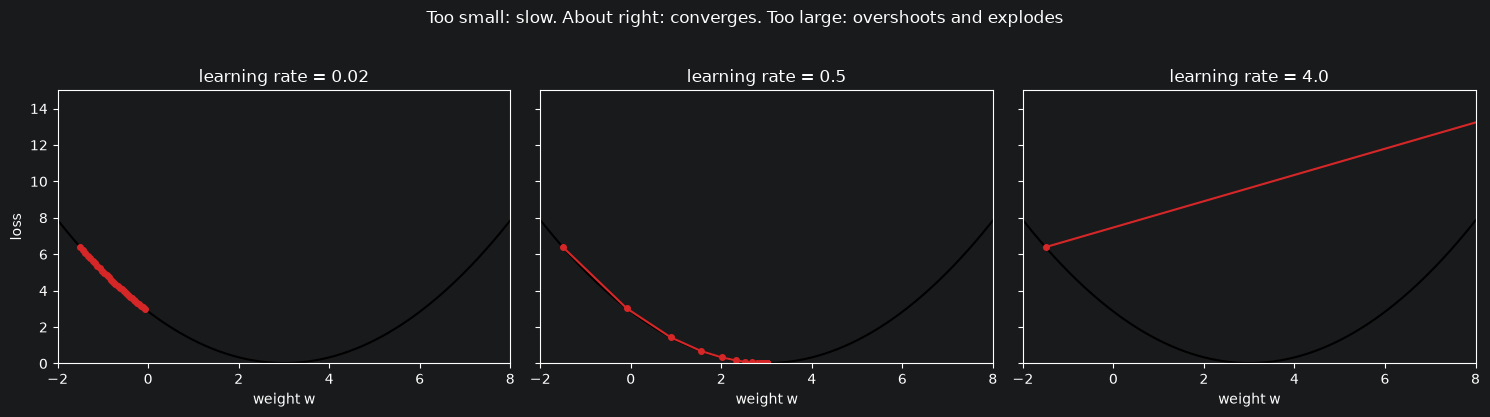

In [6]:
x_toy = rng.uniform(-1, 1, 50)
y_toy = 3.0 * x_toy + rng.normal(0, 0.2, 50)

def loss_for(w):
    return np.mean((w * x_toy - y_toy) ** 2)

def gradient_for(w):
    # derivative of the mean squared error with respect to w
    return np.mean(2 * (w * x_toy - y_toy) * x_toy)

def descend(start, learning_rate, steps=30):
    path = [start]
    for _ in range(steps):
        path.append(path[-1] - learning_rate * gradient_for(path[-1]))
    return np.array(path)

w_grid = np.linspace(-2, 8, 200)
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, rate in zip(axes, [0.02, 0.5, 4.0]):
    path = descend(start=-1.5, learning_rate=rate)
    ax.plot(w_grid, [loss_for(v) for v in w_grid], color="black")
    ax.plot(path, [loss_for(v) for v in path], "o-", color="tab:red", markersize=4)
    ax.set_title(f"learning rate = {rate}")
    ax.set_xlabel("weight w"); ax.set_xlim(-2, 8); ax.set_ylim(0, 15)
axes[0].set_ylabel("loss")
plt.suptitle("Too small: slow. About right: converges. Too large: overshoots and explodes", y=1.03)
plt.tight_layout(); plt.show()

- **Left (0.02):** every step is safe, but 30 steps are not enough to arrive.
- **Middle (0.5):** the steps get smaller as the slope flattens, and we settle at the bottom (near 3, the true value).
- **Right (4.0):** each step overshoots the bottom by more than the last one, so the loss grows instead of shrinking, and the weight is thrown further and further out of the picture. This is what a learning rate that is too high looks like in a real network: the loss shoots up or turns into `nan`.

The learning rate is the most important setting in neural network training.

## Step 5: Train a Neuron From Scratch

Now a neuron with **two** inputs and a bias (so, a linear regression), trained with gradient descent. For the mean squared error the gradients have a simple form:

- for the weights: `gradient = (2/n) * X^T (prediction - y)`
- for the bias: `gradient = 2 * mean(prediction - y)`

We then check the answer against the closed-form solution of linear regression from scikit-learn.

Gradient descent found w = [ 1.499 -2.012] , b = 0.695
scikit-learn found      w = [ 1.499 -2.012] , b = 0.695


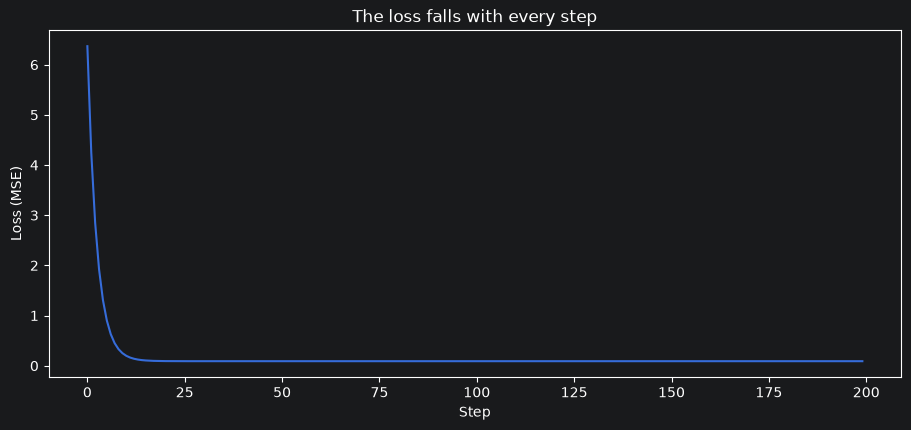

In [7]:
n = 300
X_lin = rng.normal(0, 1, (n, 2))
true_w, true_b = np.array([1.5, -2.0]), 0.7
y_lin = X_lin @ true_w + true_b + rng.normal(0, 0.3, n)

w_hat = np.zeros(2)
b_hat = 0.0
learning_rate = 0.1
history = []

for step in range(200):
    prediction = X_lin @ w_hat + b_hat
    error = prediction - y_lin
    history.append(np.mean(error ** 2))
    w_hat -= learning_rate * (2 / n) * X_lin.T @ error
    b_hat -= learning_rate * 2 * np.mean(error)

print("Gradient descent found w =", np.round(w_hat, 3), ", b =", round(b_hat, 3))

from sklearn.linear_model import LinearRegression
check = LinearRegression().fit(X_lin, y_lin)
print("scikit-learn found      w =", np.round(check.coef_, 3), ", b =", round(float(check.intercept_), 3))

plt.plot(history); plt.xlabel("Step"); plt.ylabel("Loss (MSE)"); plt.title("The loss falls with every step")
plt.show()

Gradient descent has found the same weights as the exact algebraic solution. A neuron trained this way **is** linear regression. The power of a neural network does not come from the neuron but from **stacking neurons in layers with bends between them**, which we do next.

## Step 6: Why One Neuron Is Not Enough

Here is a relationship that a linear model cannot learn. The target `y` depends on the **product** of two inputs:

`y = x1 * x2`

Financially, think of `x1` as recent momentum and `x2` as a market regime that is +1 when conditions are calm and -1 when they are stressed. Momentum predicts **gains in calm markets** and **losses in stressed ones**. A linear model can only add `a*x1 + b*x2`. It cannot say "the effect of x1 **depends on** x2". That is an **interaction**, and interactions are exactly what hidden layers learn.

R squared of a linear model (one neuron): 0.000


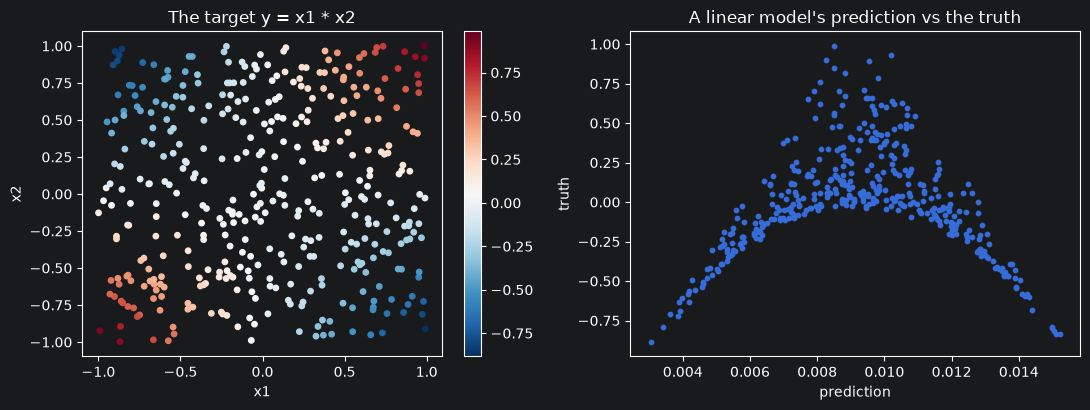

In [8]:
n = 400
X_int = rng.uniform(-1, 1, (n, 2))
y_int = X_int[:, 0] * X_int[:, 1] + rng.normal(0, 0.02, n)

linear_model = LinearRegression().fit(X_int, y_int)
r2 = linear_model.score(X_int, y_int)
print(f"R squared of a linear model (one neuron): {r2:.3f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
scatter = ax[0].scatter(X_int[:, 0], X_int[:, 1], c=y_int, cmap="RdBu_r", s=15)
ax[0].set_title("The target y = x1 * x2"); ax[0].set_xlabel("x1"); ax[0].set_ylabel("x2")
plt.colorbar(scatter, ax=ax[0])
ax[1].scatter(linear_model.predict(X_int), y_int, s=10)
ax[1].set_title("A linear model's prediction vs the truth"); ax[1].set_xlabel("prediction"); ax[1].set_ylabel("truth")
plt.tight_layout(); plt.show()

The linear model explains essentially nothing (R squared is close to 0). The picture on the left has a clear pattern: red in two opposite corners and blue in the other two. The model on the right predicts almost the same value for every point.

## Step 7: A Network With One Hidden Layer, Written From Scratch

A **hidden layer** is several neurons that read the same inputs, each with its own weights. A second set of weights then combines their outputs into the final prediction.

```
inputs (2)  ->  hidden layer (8 neurons, tanh)  ->  output (1 neuron, linear)
```

With matrices, the **forward pass** takes two lines:

```
hidden = tanh(X @ W1 + b1)       shapes: (n, 2) @ (2, 8) + (8,)  gives (n, 8)
output = hidden @ W2 + b2        shapes: (n, 8) @ (8, 1) + (1,)  gives (n, 1)
```

The **backward pass** (backpropagation) is the chain rule from calculus, applied from the end of the network back to the start. We ask, for each weight, "how much does the loss change if this weight changes a little?". The answer for a weight deep inside the network is built from the answers for the layers after it. You do not need to derive it, but read the code below and match each line with the sentence in its comment.

In [9]:
class TinyNetwork:
    """A network with one hidden layer, trained by gradient descent. Everything is visible."""

    def __init__(self, n_inputs, n_hidden, seed=0):
        r = np.random.default_rng(seed)
        # Small random starting weights. (If every weight started equal, every hidden
        # neuron would learn exactly the same thing.)
        self.W1 = r.normal(0, 0.5, (n_inputs, n_hidden))
        self.b1 = np.zeros(n_hidden)
        self.W2 = r.normal(0, 0.5, (n_hidden, 1))
        self.b2 = np.zeros(1)

    def forward(self, X):
        self.X = X
        self.hidden = np.tanh(X @ self.W1 + self.b1)          # the hidden layer
        return (self.hidden @ self.W2 + self.b2).ravel()      # the output

    def loss(self, X, y):
        return np.mean((self.forward(X) - y) ** 2)

    def gradients(self, X, y):
        n = len(y)
        prediction = self.forward(X)
        d_output = (2 / n) * (prediction - y).reshape(-1, 1)  # how the loss changes with each output
        grad_W2 = self.hidden.T @ d_output                     # ... so how it changes with W2
        grad_b2 = d_output.sum(axis=0)
        d_hidden = d_output @ self.W2.T                        # pass the blame back to the hidden layer
        d_pre = d_hidden * (1 - self.hidden ** 2)              # through tanh (its slope is 1 - tanh^2)
        grad_W1 = self.X.T @ d_pre                             # ... so how it changes with W1
        grad_b1 = d_pre.sum(axis=0)
        return grad_W1, grad_b1, grad_W2, grad_b2

    def step(self, X, y, learning_rate):
        g1, gb1, g2, gb2 = self.gradients(X, y)
        self.W1 -= learning_rate * g1; self.b1 -= learning_rate * gb1
        self.W2 -= learning_rate * g2; self.b2 -= learning_rate * gb2

### How do we know the gradients are right?

A mistake in a hand-written derivative is silent: the network still trains, only badly. The standard safeguard is a **numerical gradient check**: nudge one weight by a tiny amount, measure how much the loss actually changes, and compare with what the formula says.

In [10]:
net = TinyNetwork(n_inputs=2, n_hidden=8, seed=1)
analytic = net.gradients(X_int, y_int)[0]          # gradient with respect to W1

epsilon = 1e-6
worst = 0
for (i, j) in [(0, 0), (1, 3), (0, 7), (1, 5)]:
    original = net.W1[i, j]
    net.W1[i, j] = original + epsilon; loss_up = net.loss(X_int, y_int)
    net.W1[i, j] = original - epsilon; loss_down = net.loss(X_int, y_int)
    net.W1[i, j] = original
    numerical = (loss_up - loss_down) / (2 * epsilon)
    worst = max(worst, abs(numerical - analytic[i, j]))
    print(f"W1[{i},{j}]  formula: {analytic[i, j]: .8f}   numerical: {numerical: .8f}")
print("Largest difference:", worst)

W1[0,0]  formula: -0.00120707   numerical: -0.00120707
W1[1,3]  formula:  0.00531275   numerical:  0.00531275
W1[0,7]  formula: -0.02833308   numerical: -0.02833308
W1[1,5]  formula:  0.00535784   numerical:  0.00535784
Largest difference: 9.65787172457766e-12


R squared of the network: 0.963  (the linear model scored 0.000)


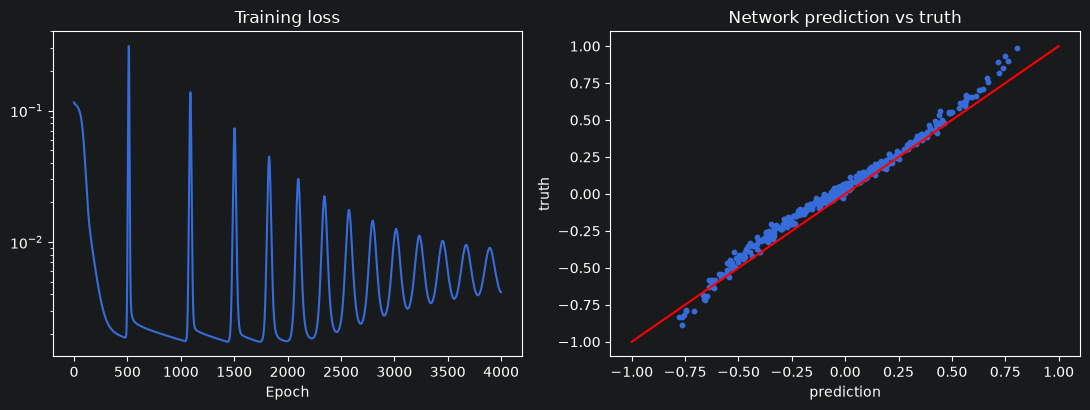

In [11]:
net = TinyNetwork(n_inputs=2, n_hidden=8, seed=1)
losses = []
for epoch in range(4000):
    net.step(X_int, y_int, learning_rate=0.3)
    losses.append(net.loss(X_int, y_int))

predicted = net.forward(X_int)
ss_res = np.sum((y_int - predicted) ** 2); ss_tot = np.sum((y_int - y_int.mean()) ** 2)
print(f"R squared of the network: {1 - ss_res / ss_tot:.3f}  (the linear model scored {r2:.3f})")

fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
ax[0].plot(losses); ax[0].set_yscale("log"); ax[0].set_title("Training loss"); ax[0].set_xlabel("Epoch")
ax[1].scatter(predicted, y_int, s=10); ax[1].plot([-1, 1], [-1, 1], color="red")
ax[1].set_title("Network prediction vs truth"); ax[1].set_xlabel("prediction"); ax[1].set_ylabel("truth")
plt.tight_layout(); plt.show()

The same data that the single neuron could not touch is now learned almost perfectly, by eight neurons with a bend in each. Each hidden neuron has found a different useful combination of `x1` and `x2`, and the output neuron has combined them.

An **epoch** is one complete pass of the training data through the network. Here we used the whole dataset in every step (**full-batch** gradient descent), so one step was one epoch.

## Step 8: The Same Network in Keras

In practice nobody writes the backward pass by hand. **Keras** (a layer on top of TensorFlow) provides ready-made layers and computes all the gradients automatically (**automatic differentiation**). The network from Step 7 takes five lines.

In [12]:
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")   # hides TensorFlow's routine start-up messages
import keras
from keras import layers
from tslab.nnutils import set_seed

set_seed(config.SEED)
model = keras.Sequential([
    layers.Input(shape=(2,)),
    layers.Dense(8, activation="tanh"),    # hidden layer: 8 neurons
    layers.Dense(1),                       # output layer: linear
])
model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.01), loss="mse")
model.summary()

ModuleNotFoundError: No module named 'keras'

Check the **Param #** column. The hidden layer has `2 inputs * 8 neurons + 8 biases = 24` parameters. The output layer has `8 * 1 + 1 = 9`. In total there are 33 numbers for the network to learn, the same as in `TinyNetwork`.

In [ ]:
history = model.fit(X_int, y_int, epochs=300, batch_size=32, verbose=0)
keras_pred = model.predict(X_int, verbose=0).ravel()
ss_res = np.sum((y_int - keras_pred) ** 2)
print(f"R squared of the Keras network: {1 - ss_res / ss_tot:.3f}")

Three new ideas appeared in that cell.

- **`batch_size=32`**: instead of using all 400 rows for every step, Keras shuffles the rows, cuts them into groups of 32 (a **mini-batch**), and takes one gradient step per group. One epoch is now 13 steps. Mini-batches are noisier but faster, and the noise helps training escape poor solutions.
- **`Adam`**: a smarter version of gradient descent. It keeps a running average of recent gradients and adapts the step size for each weight. It is a sensible default, and it is the optimiser we use for the rest of the lab.
- **`verbose=0`**: Keras does not print the training log. Change it to 1 to see the loss at every epoch.

## Step 9: Settings That Control Training

| Setting | What it is | If too small | If too large |
|:--------|:-----------|:-------------|:-------------|
| **Learning rate** | Size of each step | Training is very slow | Loss explodes or jumps around |
| **Epochs** | Number of passes through the training data | The model is under-trained | The model overfits (Step 10) |
| **Batch size** | Rows per gradient step | Noisy and slow | Smooth but may settle in a poor solution |
| **Number of neurons or layers** | Capacity of the model | Cannot represent the pattern (**underfitting**) | Memorises the training data (**overfitting**) |

We see the effect of the learning rate directly.

In [ ]:
curves = {}
for rate in [0.0001, 0.01, 0.5]:
    set_seed(config.SEED)
    m = keras.Sequential([layers.Input(shape=(2,)), layers.Dense(8, activation="tanh"), layers.Dense(1)])
    m.compile(optimizer=keras.optimizers.Adam(learning_rate=rate), loss="mse")
    curves[rate] = m.fit(X_int, y_int, epochs=150, batch_size=32, verbose=0).history["loss"]

for rate, values in curves.items():
    plt.plot(values, label=f"learning rate {rate}")
plt.yscale("log"); plt.xlabel("Epoch"); plt.ylabel("Training loss (log scale)")
plt.title("The same network with three learning rates"); plt.legend(); plt.show()

Read the three lines. The smallest rate has barely begun to learn. The middle one learns steadily. The largest bounces about and does not settle. When a training curve looks odd, check the learning rate first.

## Step 10: Overfitting, the Central Problem

A network with enough neurons can fit **any** training data perfectly, including the random noise in it. Then it has **memorised** the training set and does not generalise. We detect this by holding back a **validation set**, data that is never used to adjust the weights, and watching its loss as training goes on.

An experiment. We generate a noisy curve with only 30 training points, and give a large network plenty of epochs.

In [ ]:
NOISE = 0.4

def noisy_curve(n, seed):
    r = np.random.default_rng(seed)
    x = r.uniform(-3, 3, n)
    return x.reshape(-1, 1), np.sin(x) + r.normal(0, NOISE, n)

x_train, y_train = noisy_curve(30, seed=1)
x_valid, y_valid = noisy_curve(300, seed=2)

def big_network(l2=0.0, dropout=0.0):
    reg = keras.regularizers.l2(l2) if l2 else None
    blocks = [layers.Input(shape=(1,))]
    for _ in range(3):
        blocks.append(layers.Dense(256, activation="relu", kernel_regularizer=reg))
        if dropout:
            blocks.append(layers.Dropout(dropout))
    blocks.append(layers.Dense(1))
    m = keras.Sequential(blocks)
    m.compile(optimizer=keras.optimizers.Adam(learning_rate=0.01), loss="mse")
    return m

set_seed(config.SEED)
overfit_model = big_network()
overfit_history = overfit_model.fit(x_train, y_train, validation_data=(x_valid, y_valid),
                                    epochs=300, batch_size=30, verbose=0)

plt.plot(overfit_history.history["loss"], label="Training loss")
plt.plot(overfit_history.history["val_loss"], label="Validation loss")
best = int(np.argmin(overfit_history.history["val_loss"]))
plt.axvline(best, color="grey", linestyle="--", label=f"Best epoch ({best + 1})")
plt.yscale("log"); plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.legend()
plt.title("The training loss keeps falling. The validation loss turns around."); plt.show()

This is the signature of overfitting: the **training** loss falls steadily, while the **validation** loss reaches a minimum and then climbs. Every epoch after the dashed line makes the model better at the training data and **worse** at everything else.

Let us look at the fitted curve itself.

In [ ]:
grid_x = np.linspace(-3, 3, 300).reshape(-1, 1)
plt.scatter(x_train, y_train, color="black", s=25, label="Training points")
plt.plot(grid_x, np.sin(grid_x), color="green", linewidth=2, label="The true curve")
plt.plot(grid_x, overfit_model.predict(grid_x, verbose=0), color="red", label="The overfitted network")
plt.legend(); plt.title("The network chases the noise"); plt.show()

### Three ways to fight overfitting

1. **Early stopping.** Stop training when the validation loss stops improving, and go back to the best weights. This is simple and very effective.
2. **L2 regularisation (weight decay).** Add a penalty on the size of the weights to the loss, so that the network prefers smooth, simple solutions. (The same idea as Ridge regression in Notebook 4.)
3. **Dropout.** During training, randomly switch off a fraction of the neurons at each step, so that no single neuron can be relied on. This works like training many smaller networks and averaging them. Dropout is switched **off** when the model makes predictions.

We compare them on the same data.

In [ ]:
results = {"No protection": {"Final training loss": overfit_history.history["loss"][-1],
                             "Validation loss": overfit_history.history["val_loss"][-1]}}
fits = {"No protection": overfit_model}

setups = {
    "L2 regularisation": dict(l2=0.001),
    "Dropout 30%": dict(dropout=0.3),
}
for name, options in setups.items():
    set_seed(config.SEED)
    m = big_network(**options)
    h = m.fit(x_train, y_train, validation_data=(x_valid, y_valid), epochs=300, batch_size=30, verbose=0)
    fits[name] = m
    results[name] = {"Final training loss": h.history["loss"][-1], "Validation loss": h.history["val_loss"][-1]}

# Early stopping on the unprotected network
set_seed(config.SEED)
m = big_network()
stopper = keras.callbacks.EarlyStopping(monitor="val_loss", patience=30, restore_best_weights=True)
h = m.fit(x_train, y_train, validation_data=(x_valid, y_valid), epochs=300, batch_size=30, verbose=0, callbacks=[stopper])
fits["Early stopping"] = m
results["Early stopping"] = {"Final training loss": h.history["loss"][-1], "Validation loss": min(h.history["val_loss"])}

print(f"The noise alone sets a floor: no model can go below a loss of about {NOISE ** 2:.2f}")
display(pd.DataFrame(results).T.round(4))

fig, axes = plt.subplots(1, 4, figsize=(17, 3.6), sharey=True)
for ax, (name, m) in zip(axes, fits.items()):
    ax.scatter(x_train, y_train, color="black", s=12)
    ax.plot(grid_x, np.sin(grid_x), color="green")
    ax.plot(grid_x, m.predict(grid_x, verbose=0), color="red")
    ax.set_title(name)
plt.tight_layout(); plt.show()

The validation loss column is the one that matters. Compare each protected network with the unprotected one: the protected ones should have a lower validation loss, and their red curves should be smoother and closer to the green line. The noise in the data (a standard deviation of 0.4, so a variance of 0.16) sets a **floor** on the loss that no model can go below, so do not expect any of them to reach zero.

### Why this matters even more in finance

In the example above, the signal (a sine wave with amplitude 1) was **larger** than the noise (0.35). In daily stock returns the situation is the reverse: the predictable part is tiny and the random part is large. A neural network does not know that. It will **happily fit the noise** if you let it.

We demonstrate with the most extreme case. The inputs and the target below are **pure random numbers**: there is nothing to learn. We train a moderately sized network and look at what the training loss does.

In [ ]:
r = np.random.default_rng(7)
X_noise = r.normal(0, 1, (600, 20))
y_noise = r.normal(0, 1, 600)                       # a target with no relation to the inputs at all
X_noise_valid = r.normal(0, 1, (600, 20))
y_noise_valid = r.normal(0, 1, 600)

set_seed(config.SEED)
noise_model = keras.Sequential([
    layers.Input(shape=(20,)),
    layers.Dense(64, activation="relu"), layers.Dense(64, activation="relu"), layers.Dense(1),
])
noise_model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.003), loss="mse")
noise_history = noise_model.fit(X_noise, y_noise, validation_data=(X_noise_valid, y_noise_valid),
                                epochs=300, batch_size=64, verbose=0)

plt.plot(noise_history.history["loss"], label="Training loss")
plt.plot(noise_history.history["val_loss"], label="Validation loss")
plt.axhline(1.0, color="grey", linestyle="--", label="Loss of always predicting 0 (the best possible here)")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.legend()
plt.title("A network 'learning' pure noise"); plt.show()

The network drives its **training** loss well below 1.0, which is the best that any honest model can do on this data, while the **validation** loss rises above 1.0. It has memorised 600 random numbers.

**The training loss tells you nothing about whether the model has learned anything real.** Only data the model has never seen can tell you that. This is the reason that Notebook 6 uses a validation block, early stopping, and walk-forward testing for every network, and compares every result with the naive forecast.

## Step 11: Networks That Read Sequences

The network in Step 8 treats its inputs as an unordered list. If you give it the last 20 daily returns, it does not know that the numbers form a **sequence**, or that the 20th is more recent than the 1st. Sequence networks are built to use order. Notebook 6 uses five designs, and here we look inside each one, with tiny examples.

### 11.1 The recurrent idea (RNN)

A **recurrent neural network** reads a sequence one step at a time and carries a **hidden state** `h`, its memory of what it has seen so far:

`h_t = tanh( Wx * x_t + Wh * h_(t-1) + b )`

At each step the new state depends on the new input and on the **previous state**. The final state summarises the whole sequence, and is used to make the prediction. We unroll it over a short sequence.

In [ ]:
sequence = np.array([[0.2], [-0.5], [0.1], [0.9], [-0.3]])     # five days, one feature each

Wx = np.array([[0.8]])      # how the input affects the memory
Wh = np.array([[0.6]])      # how the old memory carries forward
b = np.array([0.0])

h = np.zeros(1)
print("day   input   memory h after reading it")
for day, x_t in enumerate(sequence, start=1):
    h = np.tanh(x_t @ Wx + h @ Wh + b)
    print(f"{day:>3}   {x_t[0]:>5.1f}   {h[0]: .4f}")

Watch the memory. It changes a little with each input, and it is influenced by **every** earlier input, because each state is built from the one before.

**The problem with plain RNNs: vanishing gradients.** During training, the learning signal for an input from 30 days ago has to travel back through 30 steps, being multiplied by a factor at each step. If that factor is below 1, the signal shrinks towards zero.

In [ ]:
for factor in (0.9, 0.7, 0.5):
    print(f"factor {factor}: signal left after 5 steps = {factor**5:.4f}, 20 steps = {factor**20:.6f}, 50 steps = {factor**50:.2e}")

After 50 steps, a factor of 0.7 leaves a signal of about 2e-8, which is nothing. A plain RNN therefore cannot learn from events far back. It has a short effective memory, however long the input window is. The LSTM and GRU were invented to solve exactly this.

### 11.2 The LSTM

A **Long Short-Term Memory** cell has, in addition to the hidden state, a **cell state** `c`: a conveyor belt that carries information along the sequence with only small, controlled changes, so that the learning signal can travel back along it without vanishing.

The cell uses three **gates**. A gate is a layer with a sigmoid output between 0 (closed) and 1 (open) that multiplies something else. Think of the LSTM as a person keeping notes:

| Gate | Question it answers | Analogy |
|:-----|:--------------------|:--------|
| **Forget gate** `f` | How much of the old memory should I keep? | Erasing old notes |
| **Input gate** `i` | How much of the new information should I write down? | Deciding what is worth writing |
| **Output gate** `o` | How much of the memory should I reveal right now? | Choosing what to say out loud |

and a **candidate** `g` (a tanh layer) that proposes what to write. The update is:

```
c_t = f * c_(t-1) + i * g        (forget some old memory, add some new)
h_t = o * tanh(c_t)              (reveal part of the memory)
```

One step of an LSTM, with every number printed:

In [ ]:
sigmoid = lambda v: 1 / (1 + np.exp(-v))

r = np.random.default_rng(3)
n_in, n_hidden = 3, 4
# One weight matrix per gate: they all read the same combined [input, previous hidden state]
W = {gate: r.normal(0, 0.6, (n_in + n_hidden, n_hidden)) for gate in "figo"}
bias = {gate: np.zeros(n_hidden) for gate in "figo"}
bias["f"] += 1.0          # a common trick: start with the forget gate open, so memory is kept at first

x_t = np.array([1.5, -4.0, 0.8])           # today's inputs
h_prev = np.zeros(n_hidden)                 # yesterday's output
c_prev = np.array([0.5, -0.2, 0.8, 0.1])    # yesterday's memory

combined = np.concatenate([x_t, h_prev])
f = sigmoid(combined @ W["f"] + bias["f"])      # forget gate
i = sigmoid(combined @ W["i"] + bias["i"])      # input gate
g = np.tanh(combined @ W["g"] + bias["g"])      # candidate new memory
o = sigmoid(combined @ W["o"] + bias["o"])      # output gate

c_t = f * c_prev + i * g
h_t = o * np.tanh(c_t)

print("forget gate f   :", np.round(f, 3), "   (near 1 = keep the old memory)")
print("input gate i    :", np.round(i, 3), "   (near 1 = write the new information)")
print("candidate g     :", np.round(g, 3))
print("output gate o   :", np.round(o, 3))
print()
print("old memory c_prev:", c_prev)
print("new memory c_t   :", np.round(c_t, 3))
print("output h_t       :", np.round(h_t, 3))

Each of the four memory cells has its own gate values. In a trained network the gates learn **when** to remember and **when** to forget: for example, to hold on to the memory of a volatility spike for a few weeks, and to forget a quiet day immediately.

The parameter count of an LSTM is **four times** that of a plain RNN of the same size (one weight matrix for each of the three gates and one for the candidate). That is why LSTMs overfit more easily than their reputation suggests, particularly on small datasets.

### 11.3 The GRU

A **Gated Recurrent Unit** is a lighter relative of the LSTM. It merges the memory and the output into a single state, and uses **two** gates (reset and update) instead of three. It has about 25 percent fewer parameters, trains faster, and often performs about as well. When data is limited, which is the case in finance, the GRU is a sensible first choice.

### 11.4 The 1D convolutional network (CNN)

A **convolution** slides a small **filter** (a short list of weights) along the sequence. At every position, it multiplies the filter with the values under it and adds them up. The filter responds strongly when the data under it looks like the pattern it has learned. Different filters detect different **local patterns**. The same filter is used at every position, so it detects the pattern wherever it occurs.

An example with a filter written by hand, which responds to "two down days followed by an up day":

In [ ]:
returns = np.array([0.01, 0.00, -0.02, -0.01, 0.03, 0.01, -0.01, -0.02, 0.02, 0.00])
detector = np.array([-1.0, -1.0, 1.0])       # negative weights for two down days, positive for the up day

# Slide the filter along the returns, multiply, and add up at every position
response = np.correlate(returns, detector, mode="valid")

fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=False)
axes[0].bar(range(len(returns)), returns, color=["tab:green" if v >= 0 else "tab:red" for v in returns])
axes[0].set_title("Daily returns")
axes[1].bar(range(1, 1 + len(response)), response, color="tab:blue")
axes[1].set_title("Filter response: large where 'down, down, up' occurs")
plt.tight_layout(); plt.show()
print("Filter response:", np.round(response, 3))

In a trained CNN the filters are **learned**, not written by hand, and there are many of them. They are cheap, fast, and they work well when the useful information is in short local shapes. They see only a few days at a time (the filter length); stacking layers widens the view.

### 11.5 Attention and the Transformer

An RNN passes information along the sequence step by step. **Attention** lets every position look **directly** at every other position and decide how much to borrow from it. For each day, the model computes a score against every other day, turns the scores into weights that sum to 1 (a **softmax**), and takes the weighted average of the days' information.

An example with five days. We build a small score matrix by comparing every day's vector with every other day's vector:

In [ ]:
r = np.random.default_rng(5)
days = ["Mon", "Tue", "Wed", "Thu", "Fri"]
vectors = r.normal(0, 1, (5, 4))                    # one 4-number description of each day (made up)

scores = vectors @ vectors.T / np.sqrt(vectors.shape[1])        # how similar is day i to day j?
weights = np.exp(scores) / np.exp(scores).sum(axis=1, keepdims=True)   # softmax: each row sums to 1

plt.figure(figsize=(5.5, 4.5))
plt.imshow(weights, cmap="Blues")
plt.xticks(range(5), days); plt.yticks(range(5), days)
plt.xlabel("Day being looked at"); plt.ylabel("Day doing the looking")
for i in range(5):
    for j in range(5):
        plt.text(j, i, f"{weights[i, j]:.2f}", ha="center", va="center")
plt.title("Attention weights (each row sums to 1)")
plt.colorbar(); plt.tight_layout(); plt.show()

Read a row: "when processing Friday, Friday pays this much attention to Monday, to Tuesday, ..." The weights are computed from the data, so they can change from one sequence to the next. A real **Transformer** has several such attention "heads", each looking for a different kind of relationship, plus a **position embedding** (attention alone has no sense of order, so we must tell it which day is which), plus a feed-forward block, residual connections and normalisation.

Transformers are the architecture behind modern language models. They excel when there is a very large amount of data. With a few thousand daily rows, they have little advantage and a lot of capacity to overfit, and Notebook 6 lets you see that for yourself.

### 11.6 Choosing an architecture

| Architecture | Reads the sequence by | Strength | Weakness | Parameters |
|:-------------|:----------------------|:---------|:---------|:-----------|
| **Feed-forward (MLP)** | Flattening it into one long row | Simple, fast, a strong baseline | Ignores order | Grows with the window length |
| **1D CNN** | Sliding short filters | Fast, finds local patterns | Short field of view | Few |
| **RNN** | Stepping through, carrying a state | Natural for sequences | Forgets (vanishing gradients) | Few |
| **LSTM** | Stepping through, with gated memory | Can keep long-range information | Slow, many parameters, overfits small data | Many |
| **GRU** | Like an LSTM with two gates | Lighter than the LSTM | Slightly less flexible | Fewer than the LSTM |
| **Transformer** | Attention between all positions | Captures long-range relations in parallel | Needs a lot of data; many parameters | Many |

None of these is "best". For a few thousand rows of noisy daily data, the **simplest** architecture that can capture the pattern usually wins, and Notebook 6 tests that claim.

## Step 12: Check Your Understanding

Try to answer these without scrolling up. The answers are in the next cell.

1. A neuron has weights `[2, -1]`, a bias of `0.5`, and inputs `[1, 3]`. With a ReLU activation, what is its output?
2. Your training loss falls every epoch but your validation loss has been rising for the last 20 epochs. What is happening, and what do you do?
3. Why does a stack of ten layers with **no** activation functions have no more power than a single layer?
4. Your training loss suddenly becomes `nan` after a few epochs. What is the first setting you change?
5. Why is a validation set different from a test set? Which one may you use to choose the number of epochs?
6. Name one reason an LSTM may have trouble with 20 years of daily returns even though it was designed to remember long sequences.
7. You train a network on stock returns and get a training loss far below the loss of "always predict zero", but the validation loss is slightly above it. What does that tell you?

<details>
<summary>Click to show the answers</summary>

1. `2*1 + (-1)*3 + 0.5 = -0.5`. ReLU turns a negative number into 0, so the output is **0**.
2. The network is **overfitting**. Stop training at the epoch with the lowest validation loss (early stopping). You can also add L2 regularisation or dropout, or reduce the size of the network.
3. Each layer without an activation function is a linear transformation, and a linear transformation of a linear transformation is still a linear transformation. The whole stack can be replaced by one matrix.
4. The **learning rate**. It is almost certainly too high. Reduce it by a factor of 10.
5. The validation set is used **during** development to make decisions (the number of epochs, the architecture, the hyperparameters). The test set is used **once**, at the end, to report the honest performance. If you use the test set to make decisions, it is no longer a test.
6. The usable history is limited by how much **signal** there is, not by the length of the window. Most of the old data is noise, and the market's behaviour changes over time (regimes), so a long memory can mean memorising conditions that no longer apply. Also, 20 years of daily data is only about 5000 rows, which is small for a model with thousands of parameters.
7. The model has **memorised noise**. A training loss far below the naive loss, with no improvement on unseen data, is the signature of overfitting. The model has not learned a real pattern.

</details>

## Step 13: Exercises

1. In Step 7, change the number of hidden neurons from 8 to 2, and then to 32. What happens to the final R squared? Explain.
2. In Step 4, find by experiment the largest learning rate (to one decimal place) for which gradient descent still converges for the toy problem.
3. In Step 6, create a new target `y = x1 + x2`. Does the linear model now succeed? What does that tell you about **when** a neural network is worth using over a linear model?
4. In the overfitting experiment (Step 10), change the training set size from 30 to 300 points. Does overfitting get better or worse? What is the lesson for a dataset with only 2800 rows?
5. In Step 10, try L2 values of 0.0001, 0.001, 0.01 and 0.1. Plot the final validation loss against the L2 value. What happens when the penalty is too strong?
6. Modify the LSTM step in Step 11.2 so that the forget gate is forced to 0. What does the new memory `c_t` become?

## Summary

- A neuron is a weighted sum plus a bend (an activation). A network is many neurons in layers.
- **Learning** means reducing a loss by gradient descent. The **learning rate** is the most important setting.
- Hidden layers and activations let a network learn **non-linear relationships and interactions**. A single neuron is only linear regression.
- Frameworks such as Keras compute the gradients automatically, but the ideas you saw in NumPy are exactly what they do.
- **Overfitting** is the central danger. A falling training loss proves nothing, and a network will fit pure noise if allowed. Use a validation set, early stopping, regularisation and dropout.
- Sequence networks (RNN, LSTM, GRU, 1D CNN, Transformer) read a window of days in different ways. The simplest one that works is usually the best choice when data is limited and noisy.